In [1]:
# Environment setup & Imports
import os, sys
sys.path.append(os.path.abspath('..'))
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import ipywidgets as widgets
from IPython.display import display, HTML

from shared_utils.theme import PALETTE, apply_sleek_theme, create_dashboard_header
from lorenz_engine import compute_lorenz_equilibria, simulate_lorenz, simulate_butterfly_divergence
from poincare_and_lorenz_map import extract_poincare_section, compute_lorenz_cusp_map

apply_sleek_theme()
display(HTML(create_dashboard_header(
    'ACT 05: LORENZ ATTRACTOR & 3D CONTINUOUS CHAOS',
    'Interactive GUI Suite: 3D Butterfly Topology, SDIC Horizon & 1D Cusp Return Map'
)))

In [2]:
# LAB 5.1: 3D LORENZ ATTRACTOR GEOMETRY & PROJECTIONS
display(HTML(create_dashboard_header(
    'LAB 5.1: 3D STRANGE ATTRACTOR & RAYLEIGH PARAMETER EXPLORER',
    'Adjust parameter r (Rayleigh number) to witness transition from fixed point sinks to the chaotic butterfly.'
)))

def render_lorenz_3d(r_val, sigma_val, elev_angle, azim_angle):
    t_pts, x_pts, y_pts, z_pts = simulate_lorenz(r=r_val, sigma=sigma_val, t_span=(0.0, 35.0), dt=0.01)
    eqs, div_f, r_hopf = compute_lorenz_equilibria(r=r_val, sigma=sigma_val)
    
    fig = plt.figure(figsize=(13, 5.5), dpi=100)
    # Panel A: 3D Perspective Projection
    ax3d = fig.add_subplot(1, 2, 1, projection='3d')
    ax3d.set_facecolor(PALETTE['surface'])
    ax3d.plot(x_pts, y_pts, z_pts, color=PALETTE['cyan'], lw=0.7, alpha=0.85)
    for eq in eqs:
        c = eq['coord']
        ax3d.scatter([c[0]], [c[1]], [c[2]], color=PALETTE['crimson'], s=40, edgecolors=PALETTE['text_main'])
    ax3d.view_init(elev=elev_angle, azim=azim_angle)
    ax3d.set_title('3D Phase Space (x, y, z) | div = {:.2f}'.format(div_f), fontsize=11)
    ax3d.set_xlabel('x', fontsize=9)
    ax3d.set_ylabel('y', fontsize=9)
    ax3d.set_zlabel('z', fontsize=9)
    
    # Panel B: 2D Projection (x vs z - Butterfly Wings)
    ax2d = fig.add_subplot(1, 2, 2)
    ax2d.plot(x_pts, z_pts, color=PALETTE['amber'], lw=0.6, alpha=0.85)
    for eq in eqs:
        c = eq['coord']
        ax2d.scatter([c[0]], [c[2]], color=PALETTE['crimson'], s=60, edgecolors=PALETTE['text_main'], zorder=6)
    regime = 'Chaotic Butterfly Attractor' if r_val > 24.74 else 'Stable Inward Spiral'
    ax2d.set_title('2D Wing Projection (x vs z) | ' + regime, fontsize=11)
    ax2d.set_xlabel('Convection Velocity x', fontsize=10)
    ax2d.set_ylabel('Temperature Inversion z', fontsize=10)
    
    plt.tight_layout()
    plt.show()

s_r = widgets.FloatSlider(value=28.0, min=1.0, max=50.0, step=1.0, description='Rayleigh r:', layout=widgets.Layout(width='320px'))
s_sig = widgets.FloatSlider(value=10.0, min=2.0, max=20.0, step=0.5, description='Prandtl sigma:', layout=widgets.Layout(width='320px'))
s_elev = widgets.IntSlider(value=25, min=0, max=90, step=5, description='Elevation:', layout=widgets.Layout(width='260px'))
s_azim = widgets.IntSlider(value=45, min=-180, max=180, step=5, description='Azimuth:', layout=widgets.Layout(width='260px'))

ui_3d = widgets.VBox([
    widgets.HBox([s_r, s_sig]),
    widgets.HBox([s_elev, s_azim])
], layout=widgets.Layout(padding='10px', background_color=PALETTE['surface'], border='1px solid ' + PALETTE['border'], border_radius='8px'))

out_3d = widgets.interactive_output(render_lorenz_3d, {'r_val': s_r, 'sigma_val': s_sig, 'elev_angle': s_elev, 'azim_angle': s_azim})
display(ui_3d, out_3d)

Output()

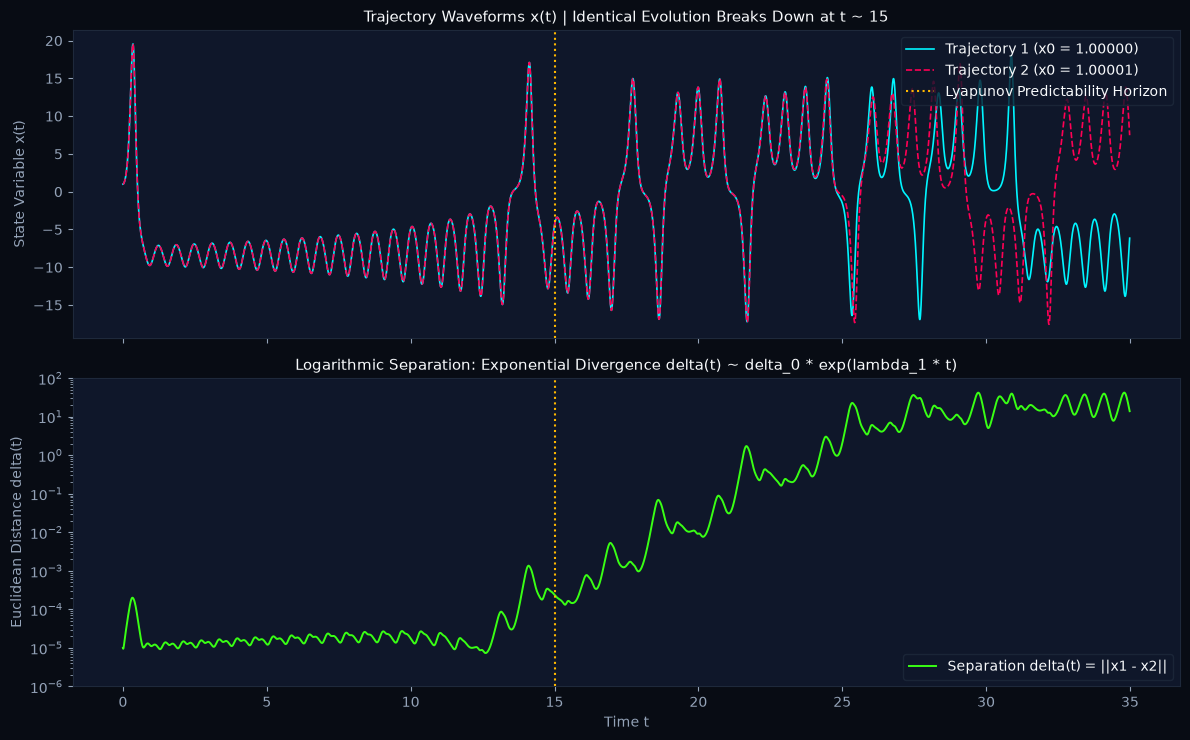

In [3]:
# LAB 5.2: THE BUTTERFLY EFFECT & EXPONENTIAL DIVERGENCE
display(HTML(create_dashboard_header(
    'LAB 5.2: THE BUTTERFLY EFFECT (SENSITIVE DEPENDENCE ON INITIAL CONDITIONS)',
    'Compare two orbits with microscopic separation delta_0 = 10^-5: Track divergence on linear and logarithmic scales.'
)))

t_arr, sol1, sol2, delta_arr = simulate_butterfly_divergence(perturbation=1e-5, t_span=(0.0, 35.0))

fig, axs = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, dpi=100)

# Panel A: State coordinate x(t) overlay
axs[0].plot(t_arr, sol1[0], color=PALETTE['cyan'], lw=1.2, label='Trajectory 1 (x0 = 1.00000)')
axs[0].plot(t_arr, sol2[0], color=PALETTE['crimson'], linestyle='--', lw=1.2, label='Trajectory 2 (x0 = 1.00001)')
axs[0].axvline(15.0, color=PALETTE['amber'], linestyle=':', lw=1.5, label='Lyapunov Predictability Horizon')
axs[0].set_title('Trajectory Waveforms x(t) | Identical Evolution Breaks Down at t ~ 15', fontsize=11)
axs[0].set_ylabel('State Variable x(t)', fontsize=10)
axs[0].legend(loc='upper right')

# Panel B: Logarithmic Separation Growth
axs[1].semilogy(t_arr, delta_arr, color=PALETTE['emerald'], lw=1.4, label='Separation delta(t) = ||x1 - x2||')
axs[1].axvline(15.0, color=PALETTE['amber'], linestyle=':', lw=1.5)
axs[1].set_title('Logarithmic Separation: Exponential Divergence delta(t) ~ delta_0 * exp(lambda_1 * t)', fontsize=11)
axs[1].set_xlabel('Time t', fontsize=10)
axs[1].set_ylabel('Euclidean Distance delta(t)', fontsize=10)
axs[1].set_ylim(1e-6, 1e2)
axs[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

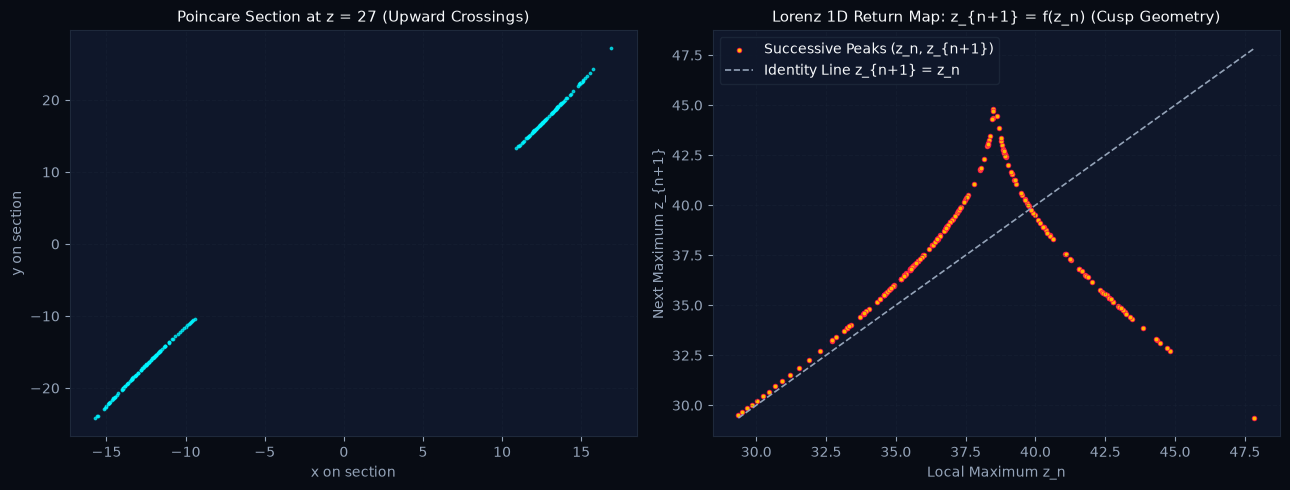

In [4]:
# LAB 5.3: POINCARE SECTION & THE 1D LORENZ CUSP MAP
display(HTML(create_dashboard_header(
    'LAB 5.3: POINCARE SECTION & LORENZ 1D CUSP RETURN MAP',
    'Extract successive local peaks z_n vs z_{n+1}: Slopes > 1 everywhere prove that no stable limit cycle can exist.'
)))

t_pts, x_pts, y_pts, z_pts = simulate_lorenz(r=28.0, sigma=10.0, t_span=(0.0, 150.0), dt=0.005)
sec_x, sec_y = extract_poincare_section(x_pts, y_pts, z_pts, z_plane=27.0)
z_n, z_next = compute_lorenz_cusp_map(z_pts)

fig, axs = plt.subplots(1, 2, figsize=(13, 5), dpi=100)

# Panel A: Poincare Section on z = 27
axs[0].scatter(sec_x, sec_y, s=3, color=PALETTE['cyan'], alpha=0.7)
axs[0].set_title('Poincare Section at z = 27 (Upward Crossings)', fontsize=11)
axs[0].set_xlabel('x on section', fontsize=10)
axs[0].set_ylabel('y on section', fontsize=10)
axs[0].grid(True, linestyle='--', alpha=0.3)

# Panel B: 1D Lorenz Cusp Map
axs[1].scatter(z_n, z_next, s=12, color=PALETTE['amber'], edgecolors=PALETTE['crimson'], lw=0.5, label='Successive Peaks (z_n, z_{n+1})')
z_line = np.linspace(min(z_n), max(z_n), 100)
axs[1].plot(z_line, z_line, color=PALETTE['text_muted'], linestyle='--', lw=1.2, label='Identity Line z_{n+1} = z_n')
axs[1].set_title('Lorenz 1D Return Map: z_{n+1} = f(z_n) (Cusp Geometry)', fontsize=11)
axs[1].set_xlabel('Local Maximum z_n', fontsize=10)
axs[1].set_ylabel('Next Maximum z_{n+1}', fontsize=10)
axs[1].legend(loc='upper left')
axs[1].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()